## Configure the run

In [14]:
from datetime import timedelta
from pathlib import Path

import numpy as np
import polars as pl
import torch
from torch import nn

feature_groups = ("transactions", "calendar", "holidays", "oil", "store", "last_year")
transaction_window = 56
impute_missing_inputs = True
run_window_comparison = False

model_seeds = (42, )
lookback = 56
origin_stride = 5
epochs = 8
batch_size = 1024
learning_rate = 0.001
hidden_widths = (128, 64)
embedding_size = 16
annual_lag = 364
days_per_week = 7
baseline_weeks = 4

available_groups = {"transactions", "calendar", "holidays", "oil", "store", "last_year"}
if unknown_groups := set(feature_groups) - available_groups:
    raise ValueError(f"Unknown feature groups: {', '.join(sorted(unknown_groups))}")
if transaction_window < 1:
    raise ValueError("transaction_window must be positive.")
if not model_seeds:
    raise ValueError("Use at least one model seed.")

use_last_year = "last_year" in feature_groups

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

raw_dir = root / "data" / "raw"
run_name = "-".join(feature_groups) or "baseline"
if len(model_seeds) > 1:
    run_name += "-ensemble"
if impute_missing_inputs:
    run_name += "-mean-imputed"
output_dir = root / "data" / "output" / run_name

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
print(f"Training device: {device}", flush=True)

Training device: cuda


## Load data and set forecast dates

Use the last forecast-length block of labeled dates for validation.

In [15]:
train = pl.read_csv(raw_dir / "train.csv", try_parse_dates=True)
test = pl.read_csv(raw_dir / "test.csv", try_parse_dates=True)
stores = pl.read_csv(raw_dir / "stores.csv").sort("store_nbr")
oil = pl.read_csv(raw_dir / "oil.csv", try_parse_dates=True)
transactions = pl.read_csv(raw_dir / "transactions.csv", try_parse_dates=True)
events = pl.read_csv(raw_dir / "holidays_events.csv", try_parse_dates=True)
sample = pl.read_csv(raw_dir / "sample_submission.csv")

series_columns = ["store_nbr", "family"]
series_day = series_columns + ["date"]
store_day = ["store_nbr", "date"]
series_keys = train.select(series_columns).unique().sort(series_columns)
first_date = train["date"].min()
last_labeled_date = train["date"].max()
test_start = last_labeled_date + timedelta(days=1)
test_dates = test["date"].unique().sort()
horizon = len(test_dates)
validation_start = test_start - timedelta(days=horizon)
split_day = (validation_start - first_date).days
test_day = (test_start - first_date).days

assert test_dates.to_list() == pl.date_range(test_start, test_dates[-1], eager=True).to_list()
assert test.height == series_keys.height * horizon
assert test.select(series_columns).unique().sort(series_columns).equals(series_keys)
assert set(series_keys["store_nbr"]).issubset(stores["store_nbr"])

calendar = pl.DataFrame({"date": pl.date_range(first_date, test_dates[-1], eager=True)})
sales_rows = pl.concat([
    train.with_columns(pl.lit("train").alias("split")),
    test.with_columns(pl.lit(None, dtype=train.schema["sales"]).alias("sales"))
    .select(train.columns)
    .with_columns(pl.lit("test").alias("split")),
])
assert sales_rows["id"].n_unique() == sales_rows.height
assert sales_rows.select(series_day).n_unique() == sales_rows.height

## Join holidays and store data

Match national, regional, and local holidays to the stores they apply to.

In [16]:
holiday_types = ("Holiday", "Transfer", "Additional", "Bridge")
scheduled = events.filter(
    ~pl.col("transferred") & pl.col("type").is_in((*holiday_types, "Work Day"))
)
holiday_rows = [
    scheduled.filter(pl.col("locale") == "National").join(
        stores.select("store_nbr"), how="cross"
    ).select(store_day + ["type"])
]
for scope, location in [("Regional", "state"), ("Local", "city")]:
    holiday_rows.append(
        scheduled.filter(pl.col("locale") == scope)
        .join(stores.select("store_nbr", pl.col(location).alias("locale_name")), on="locale_name")
        .select(store_day + ["type"])
    )
holiday_flags = pl.concat(holiday_rows).group_by(store_day).agg(
    pl.col("type").is_in(holiday_types).any().alias("holiday"),
    (pl.col("type") == "Work Day").any().alias("work_day"),
)

store_calendar = (
    stores.join(calendar, how="cross")
    .join(oil, on="date", how="left", validate="m:1")
    .join(transactions, on=store_day, how="left", validate="1:1")
    .join(holiday_flags, on=store_day, how="left", validate="1:1")
    .with_columns(pl.col("holiday", "work_day").fill_null(False))
    .sort(store_day)
)
unified = sales_rows.join(store_calendar, on=store_day, how="left", validate="m:1")
assert unified.height == sales_rows.height
assert unified.filter(pl.col("split") == "test")["sales"].null_count() == test.height

print(f"Unified table: {unified.height:,} rows, {unified.width} columns")
print(f"Training targets through {validation_start - timedelta(days=1)}")
print(f"Validation: {validation_start} to {last_labeled_date}")
print(f"Test: {test_dates[0]} to {test_dates[-1]}")
unified.head()

Unified table: 3,029,400 rows, 15 columns
Training targets through 2017-07-30
Validation: 2017-07-31 to 2017-08-15
Test: 2017-08-16 to 2017-08-31


id,date,store_nbr,family,sales,onpromotion,split,city,state,type,cluster,dcoilwtico,transactions,holiday,work_day
i64,date,i64,str,f64,i64,str,str,str,str,i64,f64,i64,bool,bool
0,2013-01-01,1,"""AUTOMOTIVE""",0.0,0,"""train""","""Quito""","""Pichincha""","""D""",13,null,null,true,false
1,2013-01-01,1,"""BABY CARE""",0.0,0,"""train""","""Quito""","""Pichincha""","""D""",13,null,null,true,false
2,2013-01-01,1,"""BEAUTY""",0.0,0,"""train""","""Quito""","""Pichincha""","""D""",13,null,null,true,false
3,2013-01-01,1,"""BEVERAGES""",0.0,0,"""train""","""Quito""","""Pichincha""","""D""",13,null,null,true,false
4,2013-01-01,1,"""BOOKS""",0.0,0,"""train""","""Quito""","""Pichincha""","""D""",13,null,null,true,false


## Build the sales panel

Keep a mask of observed sales so imputed input values stay out of the training targets.

In [17]:
series_count = series_keys.height
day_count = calendar.height
store_count = stores.height
series_store = series_keys.join(
    stores.select("store_nbr").with_row_index("store_idx"),
    on="store_nbr", how="left", validate="m:1", maintain_order="left",
)["store_idx"]

panel = (
    series_keys.join(calendar, how="cross")
    .join(unified.select(series_day + ["sales", "onpromotion"]),
          on=series_day, how="left", validate="1:1")
    .sort(series_day)
)


def tensor(values, dtype=None):
    return torch.as_tensor(np.array(values, copy=True), dtype=dtype, device=device)


panel_shape = (series_count, day_count)
log_sales = tensor(panel["sales"].fill_null(0).log1p().to_numpy().reshape(panel_shape), torch.float32)
sales_observed = tensor(panel["sales"].is_not_null().to_numpy().reshape(panel_shape))


def earlier_mean(values):
    count = values.is_not_null().cast(pl.UInt32).cum_sum()
    total = values.cast(pl.Float64).fill_null(0).cum_sum()
    return pl.when(count > 0).then(total / count).shift(1)


def same_weekday_sales_history():
    sales = pl.col("sales")
    weekday_mean = (
        sales.rolling_mean(baseline_weeks, min_samples=1).shift(1)
        .over(series_columns + ["weekday"], order_by="date")
    )
    series_mean = earlier_mean(sales).over(series_columns, order_by="date")
    filled = (
        panel.with_columns(pl.col("date").dt.weekday().alias("weekday"))
        .select(
            pl.when(pl.col("date") < test_start)
            .then(pl.coalesce(sales, weekday_mean, series_mean))
            .otherwise(None)
            .fill_null(0)
            .log1p()
        )
    )
    return tensor(filled.to_numpy().reshape(panel_shape), torch.float32)


sales_history = same_weekday_sales_history() if impute_missing_inputs else log_sales
log_promotions = tensor(
    panel["onpromotion"].fill_null(0).log1p().to_numpy().reshape(panel_shape), torch.float32
)
series_store_idx = tensor(series_store.to_numpy(), torch.long)

assert sales_observed[:, split_day:test_day].all()
assert not sales_observed[:, test_day:].any()
print(f"Calendar panel: {series_count:,} series × {day_count:,} days")

Calendar panel: 1,782 series × 1,704 days


## Prepare calendar and store features

Build features known in advance and fixed attributes such as store type.

In [18]:
calendar_names = []
store_features = store_calendar
if "calendar" in feature_groups:
    weekdays = range(1, days_per_week + 1)
    calendar_names.extend(f"weekday_{day}" for day in weekdays)
    calendar_names.extend(["midmonth_payday", "month_end_payday"])
    store_features = store_calendar.with_columns(
        *[
            (pl.col("date").dt.weekday() == day).alias(f"weekday_{day}")
            for day in weekdays
        ],
        (pl.col("date").dt.day() == 15).alias("midmonth_payday"),
        (pl.col("date") == pl.col("date").dt.month_end()).alias("month_end_payday"),
    )
if "holidays" in feature_groups:
    calendar_names.extend(["holiday", "work_day"])


future_calendar = torch.empty((store_count, day_count, 0), device=device)
if calendar_names:
    future_calendar = tensor(
        store_features.select(calendar_names).to_numpy().reshape(store_count, day_count, -1),
        torch.float32,
    )

store_feature_names = []
static_features = torch.empty((store_count, 0), device=device)
if "store" in feature_groups:
    store_categories = stores.select("type", "cluster").to_dummies()
    store_feature_names = store_categories.columns
    static_features = tensor(store_categories.to_numpy(), torch.float32)

## Prepare oil and transaction history

Use records from before each forecast start date.

In [19]:
context_names = []
oil_names = ["last_oil_price", "oil_change_7d"]
if "oil" in feature_groups:
    context_names.extend(oil_names)

transaction_mean_name = "log_transactions_mean"
transaction_coverage_name = "transaction_record_coverage"
if "transactions" in feature_groups:
    context_names.append(transaction_mean_name)
numeric_width = len(context_names)
if "transactions" in feature_groups:
    context_names.append(transaction_coverage_name)


def make_daily_oil():
    price = pl.col("dcoilwtico")
    if impute_missing_inputs:
        recent_mean = price.rolling_mean(days_per_week, min_samples=1).shift(1)
        complete_price = pl.coalesce(price, recent_mean, earlier_mean(price))
    else:
        complete_price = price.forward_fill()

    return (
        calendar.join(oil, on="date", how="left", validate="1:1")
        .sort("date")
        .with_columns(complete_price.alias("oil_price"))
        .select(
            pl.col("oil_price").shift(1).alias("last_oil_price"),
            (pl.col("oil_price").shift(1) - pl.col("oil_price").shift(days_per_week + 1))
            .alias("oil_change_7d"),
        )
        .cast(pl.Float32)
        .to_numpy()
    )


def make_raw_context(window):
    components = []
    if "oil" in feature_groups:
        daily_oil = make_daily_oil()
        components.append(np.broadcast_to(daily_oil, (store_count, day_count, len(oil_names))))
    if "transactions" in feature_groups:
        store_transactions = pl.col("transactions")
        recent_mean = (
            store_transactions.rolling_mean(window, min_samples=1).shift(1)
            .over("store_nbr")
        )
        if impute_missing_inputs:
            historical_mean = earlier_mean(store_transactions).over("store_nbr")
            recent_mean = recent_mean.fill_null(historical_mean)
        record_count = (
            store_transactions.is_not_null()
            .cast(pl.Float32)
            .rolling_sum(window, min_samples=1)
            .shift(1)
            .over("store_nbr")
        )
        transactions_by_origin = store_calendar.select(
            recent_mean.log1p().alias(transaction_mean_name),
            (record_count / window).fill_null(0).alias(transaction_coverage_name),
        ).cast(pl.Float32)
        components.append(transactions_by_origin.to_numpy().reshape(store_count, day_count, -1))

    if components:
        return np.concatenate(components, axis=-1)
    return np.empty((store_count, day_count, 0), dtype=np.float32)


raw_context = make_raw_context(transaction_window)

## Assemble model inputs

Each example is a store–family pair at a forecast start date. Fit the feature scaler on training examples.

In [20]:
history_offsets = torch.arange(-lookback, 0, device=device)
target_offsets = torch.arange(horizon, device=device)
base_input_width = (
    2 * lookback + embedding_size + horizon * (1 + len(calendar_names))
    + len(context_names) + len(store_feature_names)
)


def training_origins(target_cutoff, include_last=False):
    last_origin = target_cutoff - horizon
    origins = np.arange(lookback, last_origin + 1, origin_stride)
    if include_last and origins[-1] != last_origin:
        origins = np.append(origins, last_origin)
    return origins


def fit_context(origins, raw_features):
    if not numeric_width:
        return tensor(raw_features), {}

    numeric = raw_features[..., :numeric_width]
    training_values = numeric[:, origins, :]
    mean = np.nanmean(training_values, axis=(0, 1))
    std = np.nanstd(training_values, axis=(0, 1))
    std = np.where(std > 0, std, 1)
    scaled = np.nan_to_num((numeric - mean) / std, nan=0.0)
    values = np.concatenate([scaled, raw_features[..., numeric_width:]], axis=-1)
    return tensor(values), {"mean": mean.tolist(), "std": std.tolist()}


def model_inputs(origins, series_ids, context, include_last_year):
    rows = series_ids[:, None]
    past = origins[:, None] + history_offsets
    future = origins[:, None] + target_offsets
    store_ids = series_store_idx[series_ids]
    history_context = context[store_ids, origins]
    if include_last_year:
        previous_year = future - annual_lag
        lookup_days = previous_year.clamp_min(0)
        observed_last_year = (previous_year >= 0) & sales_observed[rows, lookup_days]
        sales_last_year = sales_history[rows, lookup_days] * (previous_year >= 0)
        history_context = torch.cat([
            history_context, sales_last_year, observed_last_year.float(),
        ], dim=1)
    return (
        series_ids,
        sales_history[rows, past],
        sales_observed[rows, past],
        log_promotions[rows, future],
        future_calendar[store_ids[:, None], future].flatten(1),
        history_context,
        static_features[store_ids],
    )

## Define the residual MLP

The network predicts a correction to a baseline built from recent sales on the same weekday.

In [21]:
class SalesForecaster(nn.Module):
    def __init__(self, include_last_year):
        super().__init__()
        self.include_last_year = include_last_year
        self.input_width = base_input_width + 2 * horizon * int(include_last_year)
        self.series_embedding = nn.Embedding(series_count, embedding_size)
        first, second = hidden_widths
        self.network = nn.Sequential(
            nn.Linear(self.input_width, first),
            nn.ReLU(),
            nn.Linear(first, second),
            nn.ReLU(),
            nn.Linear(second, horizon),
        )
        nn.init.zeros_(self.network[-1].weight)
        nn.init.zeros_(self.network[-1].bias)
        self.register_buffer("weekday_index", torch.arange(horizon) % days_per_week)

    def forward(
        self, series_id, past_sales, past_observed, future_promotions,
        calendar_features, historical_context, store_metadata,
    ):
        baseline_days = baseline_weeks * days_per_week
        weekly_shape = (-1, baseline_weeks, days_per_week)
        recent_sales = past_sales[:, -baseline_days:].reshape(weekly_shape)
        recent_observed = past_observed[:, -baseline_days:].reshape(weekly_shape)
        weekday_mean = (
            (recent_sales * recent_observed).sum(dim=1)
            / recent_observed.sum(dim=1).clamp_min(1)
        )
        baseline = weekday_mean[:, self.weekday_index]
        features = torch.cat([
            past_sales, past_observed.float(), future_promotions,
            self.series_embedding(series_id), calendar_features,
            historical_context, store_metadata,
        ], dim=1)
        return baseline + self.network(features)

## Train and score forecasts

In [22]:
@torch.inference_mode()
def predict(model, origin, context):
    model.eval()
    series_ids = torch.arange(series_count, device=device)
    origins = torch.full_like(series_ids, origin)
    inputs = model_inputs(origins, series_ids, context, model.include_last_year)
    return model(*inputs).clamp_min(0)


def forecast_rmsle(predictions, origin):
    dates = slice(origin, origin + horizon)
    mask = sales_observed[:, dates]
    errors = predictions[mask] - log_sales[:, dates][mask]
    return errors.square().mean().sqrt().item()


def fit_model(
    origins, context, epoch_count, validation_origin=None,
    *, model_seed=model_seeds[0], include_last_year=None, verbose=True, history=None,
):
    if include_last_year is None:
        include_last_year = use_last_year
    torch.manual_seed(model_seed)
    rng = np.random.default_rng(model_seed)
    model = SalesForecaster(include_last_year).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    example_count = len(origins) * series_count
    origins_on_device = tensor(origins, torch.long)
    best_score, best_epoch, best_weights = float("inf"), 0, None

    for epoch in range(1, epoch_count + 1):
        model.train()
        shuffled = tensor(rng.permutation(example_count), torch.long)
        epoch_error = torch.zeros((), device=device)
        epoch_observed = torch.zeros((), device=device)

        for ids in shuffled.split(batch_size):
            series_ids = ids % series_count
            batch_origins = origins_on_device[ids // series_count]
            future = batch_origins[:, None] + target_offsets
            target = log_sales[series_ids[:, None], future]
            mask = sales_observed[series_ids[:, None], future]

            optimizer.zero_grad(set_to_none=True)
            inputs = model_inputs(batch_origins, series_ids, context, include_last_year)
            predictions = model(*inputs)
            error_sum = ((predictions - target).square() * mask).sum()
            observed_count = mask.sum()
            loss = error_sum / observed_count.clamp_min(1)
            loss.backward()
            optimizer.step()

            epoch_error += error_sum.detach()
            epoch_observed += observed_count

        train_rmse = (epoch_error / epoch_observed).sqrt().item()
        message = f"Epoch {epoch:02d}/{epoch_count} | Train log RMSE {train_rmse:.4f}"
        if validation_origin is not None:
            score = forecast_rmsle(predict(model, validation_origin, context), validation_origin)
            message += f" | Validation RMSLE {score:.4f}"
            if history is not None:
                history.append((epoch, train_rmse, score))
            if score < best_score:
                best_score, best_epoch = score, epoch
                best_weights = {
                    name: value.detach().cpu().clone()
                    for name, value in model.state_dict().items()
                }
        if verbose:
            print(message, flush=True)

    if validation_origin is not None:
        if best_weights is None:
            raise ValueError("Training did not produce a finite validation RMSLE.")
        model.load_state_dict(best_weights)
    return model, best_epoch, best_score

## Validate on the holdout

Score the baseline and select the best epoch for each seed.

In [23]:
train_origins = training_origins(split_day)
assert train_origins[-1] + horizon <= split_day
validation_context, _ = fit_context(train_origins, raw_context)
# A zero-initialized residual returns the same-weekday baseline before fitting.
baseline_model = SalesForecaster(use_last_year).to(device)
baseline_log_sales = predict(baseline_model, split_day, validation_context)
baseline_rmsle = forecast_rmsle(baseline_log_sales, split_day)
input_width = baseline_model.input_width
del baseline_model

print(f"Training examples: {len(train_origins) * series_count:,} | MLP input width: {input_width}")
print(f"Same-weekday baseline RMSLE: {baseline_rmsle:.4f}", flush=True)
selected_members = []
validation_forecasts = []
validation_histories = []
for model_seed in model_seeds:
    history = []
    print(f"Validation fit | seed {model_seed}", flush=True)
    model, best_epoch, member_rmsle = fit_model(
        train_origins, validation_context, epochs,
        validation_origin=split_day, model_seed=model_seed, history=history,
    )
    validation_histories.append(history)
    selected_members.append((model_seed, best_epoch))
    validation_forecasts.append(predict(model, split_day, validation_context))
    print(f"Selected epoch {best_epoch} | Validation RMSLE {member_rmsle:.4f}", flush=True)

validation_log_sales = torch.stack(validation_forecasts).mean(dim=0)
best_rmsle = forecast_rmsle(validation_log_sales, split_day)
print(f"Combined validation RMSLE: {best_rmsle:.4f}", flush=True)

Training examples: 572,022 | MLP input width: 378
Same-weekday baseline RMSLE: 0.5398
Validation fit | seed 42
Epoch 01/8 | Train log RMSE 0.5983 | Validation RMSLE 0.4504
Epoch 02/8 | Train log RMSE 0.5269 | Validation RMSLE 0.4478
Epoch 03/8 | Train log RMSE 0.4921 | Validation RMSLE 0.4491
Epoch 04/8 | Train log RMSE 0.4702 | Validation RMSLE 0.4409
Epoch 05/8 | Train log RMSE 0.4554 | Validation RMSLE 0.4290
Epoch 06/8 | Train log RMSE 0.4443 | Validation RMSLE 0.4410
Epoch 07/8 | Train log RMSE 0.4359 | Validation RMSLE 0.4310
Epoch 08/8 | Train log RMSE 0.4304 | Validation RMSLE 0.4325
Selected epoch 5 | Validation RMSLE 0.4290
Combined validation RMSLE: 0.4290


## Plot training performance

The learning curves use the validation run above. 
The parameter counts compare candidate widths. 
The PNG is saved as `training_performance.png` in this run's output folder.

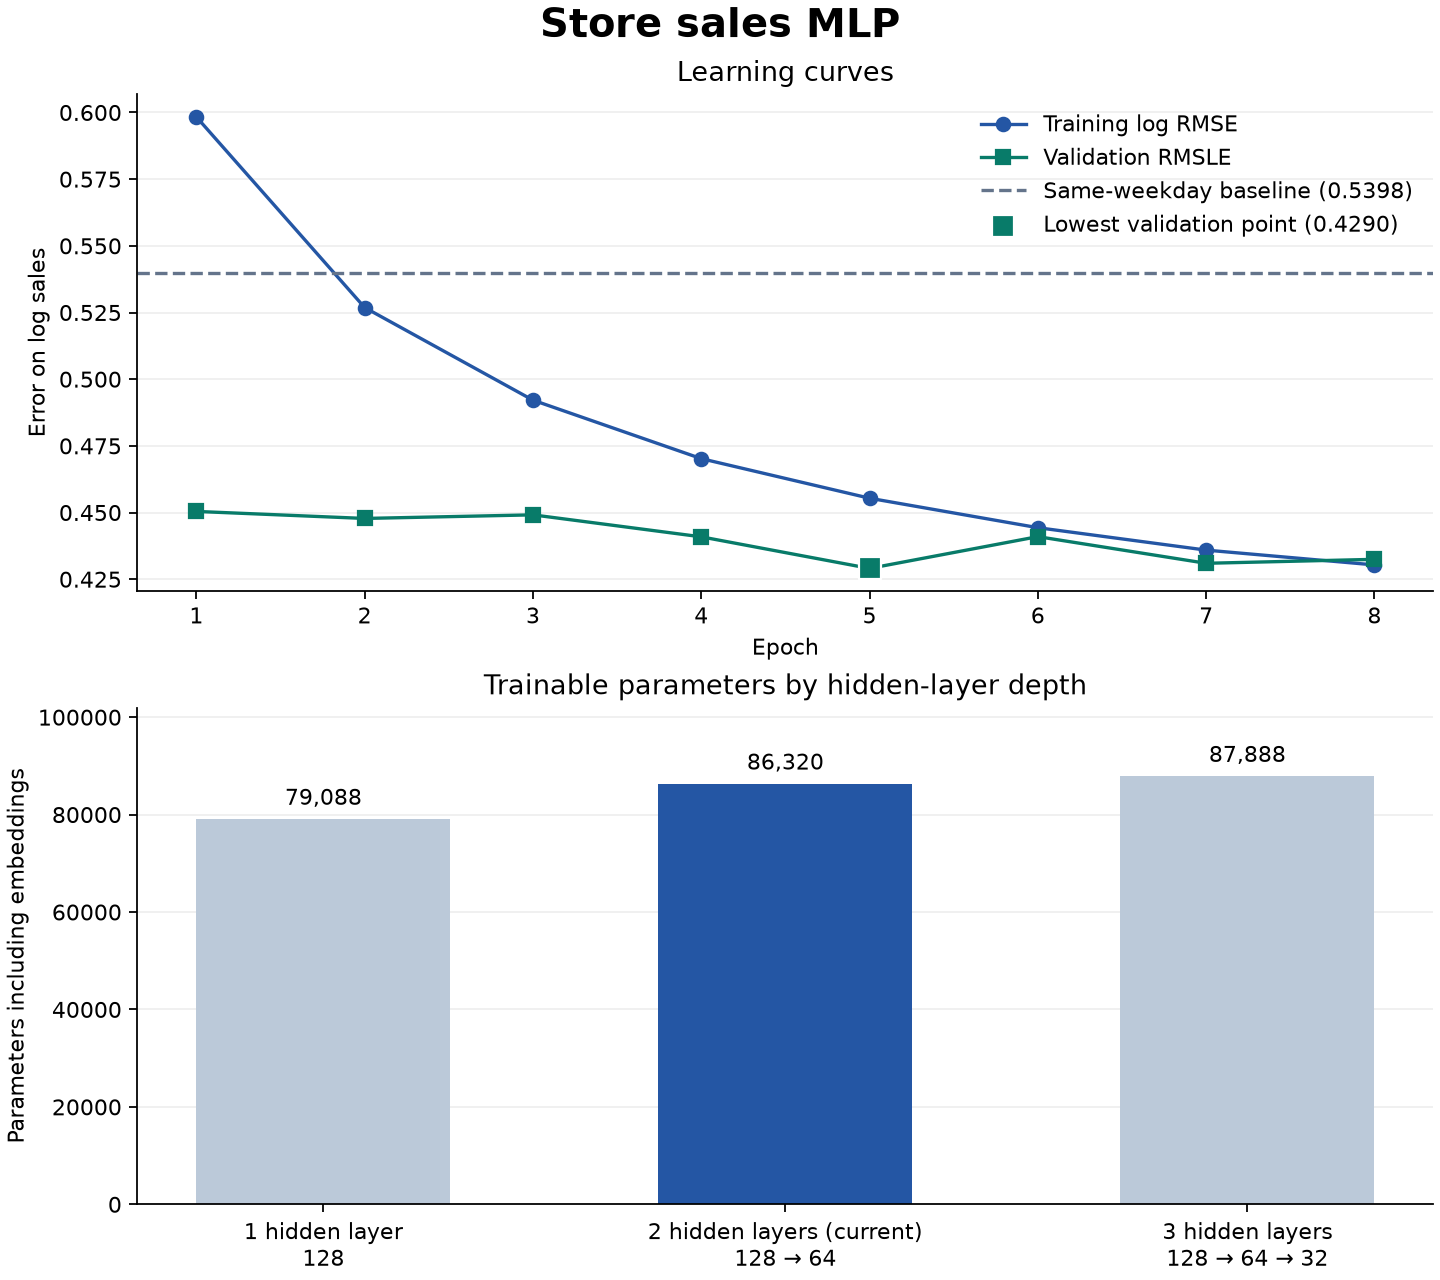

Saved training plots to d:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed\training_performance.png


In [24]:
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.dates import DateFormatter


def show_and_save_plot(figure, filename):
    output_dir.mkdir(parents=True, exist_ok=True)
    path = output_dir / filename
    figure.savefig(path, dpi=160, facecolor="white")
    plt.close(figure)
    display(Image(filename=str(path)))
    print(f"Saved plot to {path}")
    return path


history = np.asarray(validation_histories)
epoch_numbers = history[0, :, 0].astype(int)
train_curve, validation_curve = history[:, :, 1:].mean(axis=0).T
best_point = np.nanargmin(validation_curve)
label_prefix = "Mean per-seed " if len(validation_histories) > 1 else ""

fig, (learning, depth) = plt.subplots(2, 1, figsize=(9, 8), layout="constrained")
fig.suptitle("Store sales MLP", fontsize=18, fontweight="bold")

learning.plot(
    epoch_numbers, train_curve, "o-", color="#2456a4",
    label=f"{label_prefix}Training log RMSE",
)
learning.plot(
    epoch_numbers, validation_curve, "s-", color="#087b69",
    label=f"{label_prefix}Validation RMSLE",
)
learning.axhline(
    baseline_rmsle, color="#64748b", linestyle="--",
    label=f"Same-weekday baseline ({baseline_rmsle:.4f})",
)
learning.scatter(
    epoch_numbers[best_point], validation_curve[best_point],
    color="#087b69", marker="s", s=90, edgecolor="white", zorder=4,
    label=f"Lowest validation point ({validation_curve[best_point]:.4f})",
)
learning.set(title="Learning curves", xlabel="Epoch", ylabel="Error on log sales")
learning.set_xticks(epoch_numbers)
learning.legend(frameon=False)

candidate_widths = [hidden_widths[:1], hidden_widths, (*hidden_widths, 32)]
parameter_counts = []
for widths in candidate_widths:
    layer_sizes = (input_width, *widths, horizon)
    dense_parameters = sum((left + 1) * right for left, right in zip(layer_sizes, layer_sizes[1:]))
    parameter_counts.append(series_count * embedding_size + dense_parameters)

labels = [
    f"{len(widths)} hidden {'layer' if len(widths) == 1 else 'layers'}"
    f"{' (current)' if widths == hidden_widths else ''}\n{' → '.join(map(str, widths))}"
    for widths in candidate_widths
]
bars = depth.bar(labels, parameter_counts, width=0.55, color=["#bbc9d9", "#2456a4", "#bbc9d9"])
depth.bar_label(bars, labels=[f"{count:,}" for count in parameter_counts], padding=4)
depth.set(
    title="Trainable parameters by hidden-layer depth",
    ylabel="Parameters including embeddings",
    ylim=(0, max(parameter_counts) * 1.16),
)

for axis in (learning, depth):
    axis.spines[["top", "right"]].set_visible(False)
    axis.set_axisbelow(True)
    axis.grid(axis="y", alpha=0.2)

plot_path = show_and_save_plot(fig, "training_performance.png")

## Compare model and baseline errors

Use observed sales on the holdout. A positive gain means lower RMSLE for the MLP.

In [ ]:
holdout = slice(split_day, split_day + horizon)
holdout_actual = log_sales[:, holdout]
holdout_observed = sales_observed[:, holdout]
forecasts_log = torch.stack([validation_log_sales, baseline_log_sales])
squared_errors = (forecasts_log - holdout_actual).square().masked_fill(~holdout_observed, 0)

model_by_day, baseline_by_day = (
    squared_errors.sum(dim=1) / holdout_observed.sum(dim=0)
).sqrt().cpu().numpy()
forecast_days = np.arange(1, horizon + 1)

fig, axis = plt.subplots(figsize=(9, 4), layout="constrained")
axis.plot(forecast_days, model_by_day, "o-", color="#2456a4", label="MLP")
axis.plot(forecast_days, baseline_by_day, "s--", color="#64748b", label="Same-weekday baseline")
axis.set(title="RMSLE by forecast day", xlabel="Forecast day", ylabel="RMSLE")
axis.set_xticks(forecast_days)
axis.grid(axis="y", alpha=0.2)
axis.legend(frameon=False)
horizon_plot_path = show_and_save_plot(fig, "rmsle_by_forecast_day.png")

model_by_series, baseline_by_series = squared_errors.sum(dim=-1).cpu().numpy()
family_scores = (
    series_keys.with_columns(
        pl.Series("observations", holdout_observed.sum(dim=-1).cpu().numpy()),
        pl.Series("model_error", model_by_series),
        pl.Series("baseline_error", baseline_by_series),
    )
    .group_by("family")
    .agg(pl.col("observations", "model_error", "baseline_error").sum())
    .filter(pl.col("observations") > 0)
    .with_columns(
        (pl.col("model_error") / pl.col("observations")).sqrt().alias("model_rmsle"),
        (pl.col("baseline_error") / pl.col("observations")).sqrt().alias("baseline_rmsle"),
    )
    .with_columns((pl.col("baseline_rmsle") - pl.col("model_rmsle")).alias("gain"))
    .sort("gain")
)

fig, axis = plt.subplots(figsize=(9, max(5, 0.30 * family_scores.height)), layout="constrained")
gains = family_scores["gain"].to_numpy()
axis.barh(family_scores["family"].to_list(), gains, color=np.where(gains >= 0, "#087b69", "#ad4a43"))
axis.axvline(0, color="#64748b", linewidth=1)
axis.set(title="MLP gain by product family", xlabel="Same-weekday baseline RMSLE minus MLP RMSLE")
axis.set_axisbelow(True)
axis.grid(axis="x", alpha=0.2)
family_plot_path = show_and_save_plot(fig, "rmsle_gain_by_family.png")

## Inspect actual and predicted sales

Choose examples by recent sales and promotions. Each panel uses its own sales scale.

In [ ]:
recent_dates = slice(split_day - lookback, split_day)
recent_sales = log_sales[:, recent_dates].expm1()
recent_observed = sales_observed[:, recent_dates]
recent_counts = recent_observed.sum(dim=1)
recent_average = recent_sales.masked_fill(~recent_observed, 0).sum(dim=1) / recent_counts.clamp_min(1)
zero_share = ((recent_sales == 0) & recent_observed).sum(dim=1) / recent_counts.clamp_min(1)
holdout_promotions = log_promotions[:, holdout]
promo_volume = holdout_promotions.expm1().sum(dim=1)

high_volume = recent_average.argmax().item()
sparse_scores = zero_share.masked_fill((zero_share == 1) | (recent_counts == 0), -1)
sparse_scores[high_volume] = -1
intermittent = sparse_scores.argmax().item()
promo_volume[[high_volume, intermittent]] = -1
promoted = promo_volume.argmax().item()

examples = [
    ("Highest recent average sales", high_volume),
    ("Often zero in recent history", intermittent),
    ("Most items on promotion in the holdout", promoted),
]
dates = calendar["date"][holdout].to_list()
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, layout="constrained")
fig.suptitle("Actual and predicted holdout sales", fontsize=15)
for axis, (description, series_id) in zip(axes, examples, strict=True):
    store, family = series_keys.row(series_id)
    actual = holdout_actual[series_id].expm1().masked_fill(~holdout_observed[series_id], float("nan")).cpu().numpy()
    prediction = validation_log_sales[series_id].expm1().cpu().numpy()
    promotion_days = (holdout_promotions[series_id] > 0).cpu().numpy()
    axis.plot(dates, actual, "o-", color="#26374d", label="Actual")
    axis.plot(dates, prediction, "s--", color="#2456a4", label="MLP")
    axis.scatter(
        np.asarray(dates)[promotion_days], actual[promotion_days], s=85,
        facecolors="none", edgecolors="#b96a13", zorder=3, label="Promotion",
    )
    axis.set_title(f"Store {store} · {family} · {description}", loc="left", fontsize=10)
    axis.set_ylabel("Sales units")
    axis.grid(axis="y", alpha=0.2)

axes[0].legend(frameon=False, ncol=3)
axes[-1].set_xticks(dates[::max(1, horizon // 5)])
axes[-1].xaxis.set_major_formatter(DateFormatter("%b %d"))
series_plot_path = show_and_save_plot(fig, "actual_vs_predicted_sales.png")

## Backtest across three validation windows

Fit the current MLP on two earlier non-overlapping windows and reuse the latest holdout above. Each fit selects an epoch on its own window.

In [ ]:
window_rows = []
backtest_baseline = SalesForecaster(use_last_year).to(device)
for origin in (split_day - 2 * horizon, split_day - horizon):
    origins = training_origins(origin)
    assert origins[-1] + horizon <= origin
    context, _ = fit_context(origins, raw_context)
    date = calendar["date"][origin]
    print(f"Backtest starting {date}", flush=True)
    baseline_score = forecast_rmsle(predict(backtest_baseline, origin, context), origin)
    fold_predictions = []
    for seed in model_seeds:
        fold_model, _, _ = fit_model(
            origins, context, epochs, validation_origin=origin, model_seed=seed, verbose=False,
        )
        fold_predictions.append(predict(fold_model, origin, context))
    fold_log_sales = torch.stack(fold_predictions).mean(dim=0)
    window_rows.append((date, forecast_rmsle(fold_log_sales, origin), baseline_score))

window_rows.append((validation_start, best_rmsle, baseline_rmsle))
dates, model_scores, baseline_scores = zip(*window_rows, strict=True)
fig, axis = plt.subplots(figsize=(9, 4), layout="constrained")
axis.plot(dates, model_scores, "o-", color="#2456a4", label="MLP")
axis.plot(dates, baseline_scores, "s--", color="#64748b", label="Same-weekday baseline")
for date, model_score, baseline_score in window_rows:
    axis.annotate(f"{model_score:.4f}", (date, model_score), xytext=(0, 7),
                  textcoords="offset points", ha="center", color="#2456a4")
    axis.annotate(f"{baseline_score:.4f}", (date, baseline_score), xytext=(0, 7),
                  textcoords="offset points", ha="center", color="#526174")
axis.set(title="RMSLE across validation windows", xlabel="Validation window start", ylabel="RMSLE")
axis.set_xticks(dates)
axis.xaxis.set_major_formatter(DateFormatter("%b %d"))
axis.margins(x=0.10, y=0.20)
axis.grid(axis="y", alpha=0.2)
axis.legend(frameon=False)
windows_plot_path = show_and_save_plot(fig, "rmsle_by_validation_window.png")

## Optional transaction-window comparison

Set `run_window_comparison = True` and `feature_groups = ("transactions",)` to run this experiment.

In [25]:
def compare_transaction_windows(
    window_sizes=(14, 28, 56), seeds=(42, 43, 44), *, include_last_year=False,
):
    if feature_groups != ("transactions",):
        raise ValueError('Set feature_groups = ("transactions",) for a controlled comparison.')

    cutoff_days = (split_day - horizon, split_day)
    rows = []
    for window in window_sizes:
        features = make_raw_context(window)
        for cutoff in cutoff_days:
            validation_date = calendar["date"][cutoff]
            origins = training_origins(cutoff)
            context, _ = fit_context(origins, features)
            for trial_seed in seeds:
                candidate, epoch, rmsle = fit_model(
                    origins, context, epochs, validation_origin=cutoff,
                    model_seed=trial_seed, include_last_year=include_last_year, verbose=False,
                )
                del candidate
                rows.append({
                    "transaction_window": window,
                    "validation_start": validation_date,
                    "seed": trial_seed,
                    "best_epoch": epoch,
                    "rmsle": rmsle,
                })
                print(f"{window:2d} days | {validation_date} | seed {trial_seed} "
                      f"| epoch {epoch} | RMSLE {rmsle:.4f}", flush=True)
    return pl.DataFrame(rows)


if run_window_comparison:
    window_scores = compare_transaction_windows()
    print(window_scores.group_by("transaction_window").agg(
        pl.col("rmsle").mean().alias("mean_rmsle")
    ).sort("mean_rmsle"))

## Refit and forecast the test dates

Train on all labeled dates using the epoch counts selected during validation.

In [26]:
full_origins = training_origins(test_day, include_last=True)
assert full_origins[-1] + horizon == test_day
final_context, context_scaler = fit_context(full_origins, raw_context)
members = []
test_forecasts = []
for model_seed, member_epochs in selected_members:
    print(f"Final refit | seed {model_seed} | {member_epochs} epochs", flush=True)
    final_model, _, _ = fit_model(
        full_origins, final_context, member_epochs, model_seed=model_seed,
    )
    test_forecasts.append(predict(final_model, test_day, final_context))
    members.append({
        "seed": model_seed,
        "epochs": member_epochs,
        "model_state_dict": {
            name: weight.cpu() for name, weight in final_model.state_dict().items()
        },
    })

test_log_sales = torch.stack(test_forecasts).mean(dim=0)
sales_predictions = torch.expm1(test_log_sales).cpu().numpy()
assert sales_predictions.shape == (series_count, horizon)
assert np.isfinite(sales_predictions).all()

Final refit | seed 42 | 5 epochs
Epoch 01/5 | Train log RMSE 0.6007
Epoch 02/5 | Train log RMSE 0.5343
Epoch 03/5 | Train log RMSE 0.4997
Epoch 04/5 | Train log RMSE 0.4763
Epoch 05/5 | Train log RMSE 0.4616


## Save the submission and checkpoint

Match predictions to the sample submission order, then save the CSV and model weights.

In [27]:
test_ids = test.sort(series_day).select("id")
forecasts = test_ids.with_columns(pl.Series("sales", sales_predictions.ravel()))
submission = sample.select("id").join(
    forecasts, on="id", how="left", validate="1:1", maintain_order="left"
)
assert submission.height == test.height
assert submission["sales"].null_count() == 0

output_dir.mkdir(parents=True, exist_ok=True)
submission.write_csv(output_dir / "submission.csv")
checkpoint = {
    "series_keys": series_keys.rows(),
    "lookback": lookback,
    "horizon": horizon,
    "hidden_widths": hidden_widths,
    "input_width": final_model.input_width,
    "feature_groups": feature_groups,
    "impute_missing_inputs": impute_missing_inputs,
    "input_imputation": "historical_mean" if impute_missing_inputs else None,
    "transaction_window": transaction_window if "transactions" in feature_groups else None,
    "annual_lag": annual_lag if use_last_year else None,
    "calendar_features": calendar_names,
    "context_features": context_names,
    "context_scaler": context_scaler,
    "store_features": store_feature_names,
    "validation_rmsle": best_rmsle,
}
if len(members) == 1:
    checkpoint.update(members[0])
else:
    checkpoint["ensemble_members"] = members
    checkpoint["combination"] = "mean_log_sales"
torch.save(checkpoint, output_dir / "model.pt")
print(f"Refit through {last_labeled_date}. Saved {submission.height:,} forecasts to {output_dir}.")
submission.head()

Refit through 2017-08-15. Saved 28,512 forecasts to d:\Coding\yumeko\data\output\transactions-calendar-holidays-oil-store-last_year-mean-imputed.


id,sales
i64,f32
3000888,3.346626
3000889,0.002435
3000890,4.02384
3000891,1781.702271
3000892,0.0
